In [34]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from skimage.exposure import match_histograms

In [35]:
# some sort of plotting function
def histPlot(images, labels=None, graph_color="#2F3F7F", img_color="gray"):
    n_img = len(images)
    fig, ax = plt.subplots(n_img, 2, figsize=(12, 4 * n_img), squeeze=False)

    for i in range(n_img):
        arr = np.asarray(images[i], dtype=np.float32)
        if arr.max() > 1:          # PIL / uint8 → scale to 0–1
            arr /= 255.0

        ax[i][0].imshow(arr, cmap=img_color, vmin=0, vmax=1, interpolation="nearest")
        ax[i][0].axis("off")
        if labels:
            ax[i][0].set_title(labels[i])
        ax[i][1].hist(arr.ravel(), bins=64, range=(0, 1), color=graph_color)

    plt.tight_layout()

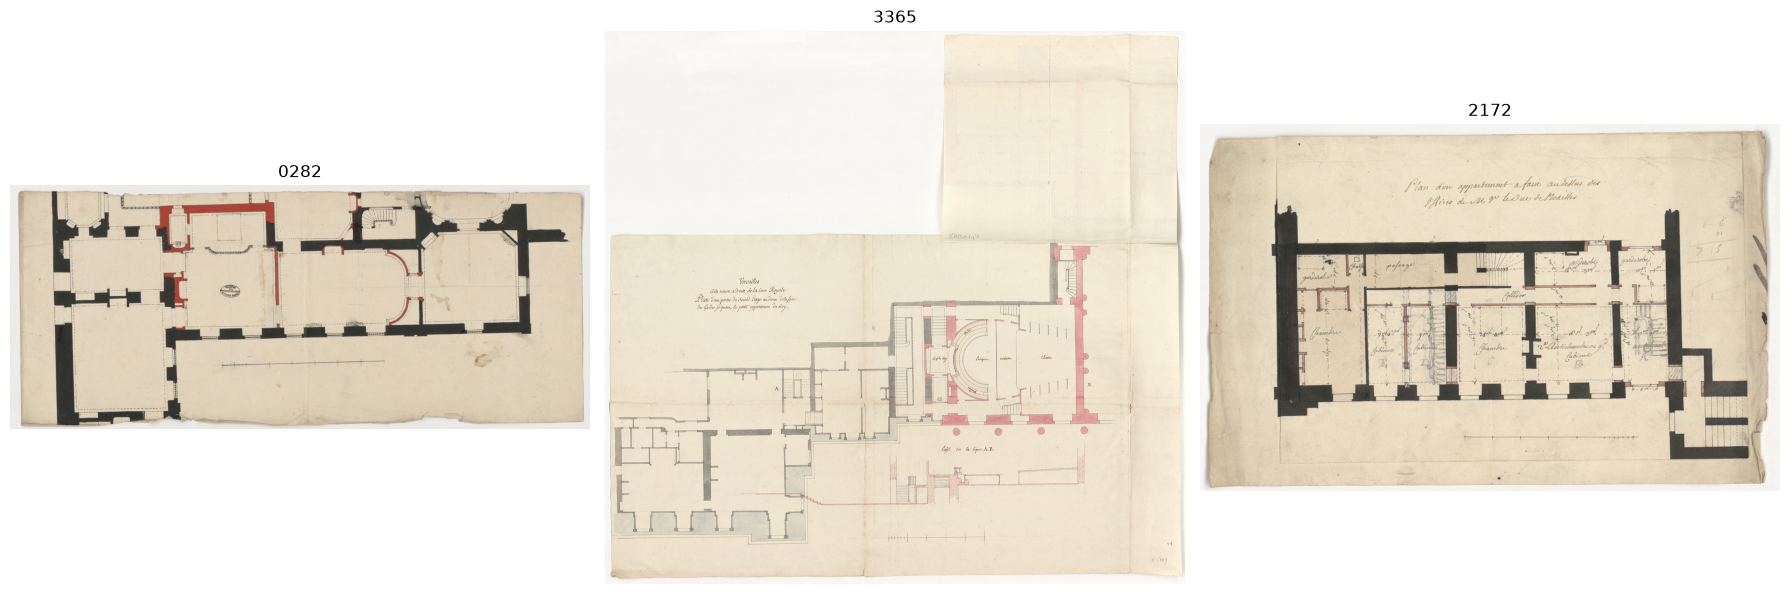

In [36]:
# Gather input images
in_dir = Path("./unprocessed")
out_dir = Path("./processed/colors")

img_ids = [
    # images to test:
    "0282", # Very bold with red walls
    "3365", # Faded image, some hashed red lines
    "2172"  # Subtle interior red walls
]
images = []

for id in img_ids:
    images.append(Image.open(in_dir / f"FRAN_0124_{id}_L.jpg"))

# Plot
fig, axes = plt.subplots(1, len(images), figsize=(6 * len(images), 6))

for ax, img, img_id in zip(axes, images, img_ids):
    ax.imshow(img.convert("RGB"))
    ax.set_title(img_id)
    ax.axis("off")

plt.tight_layout()
plt.show()



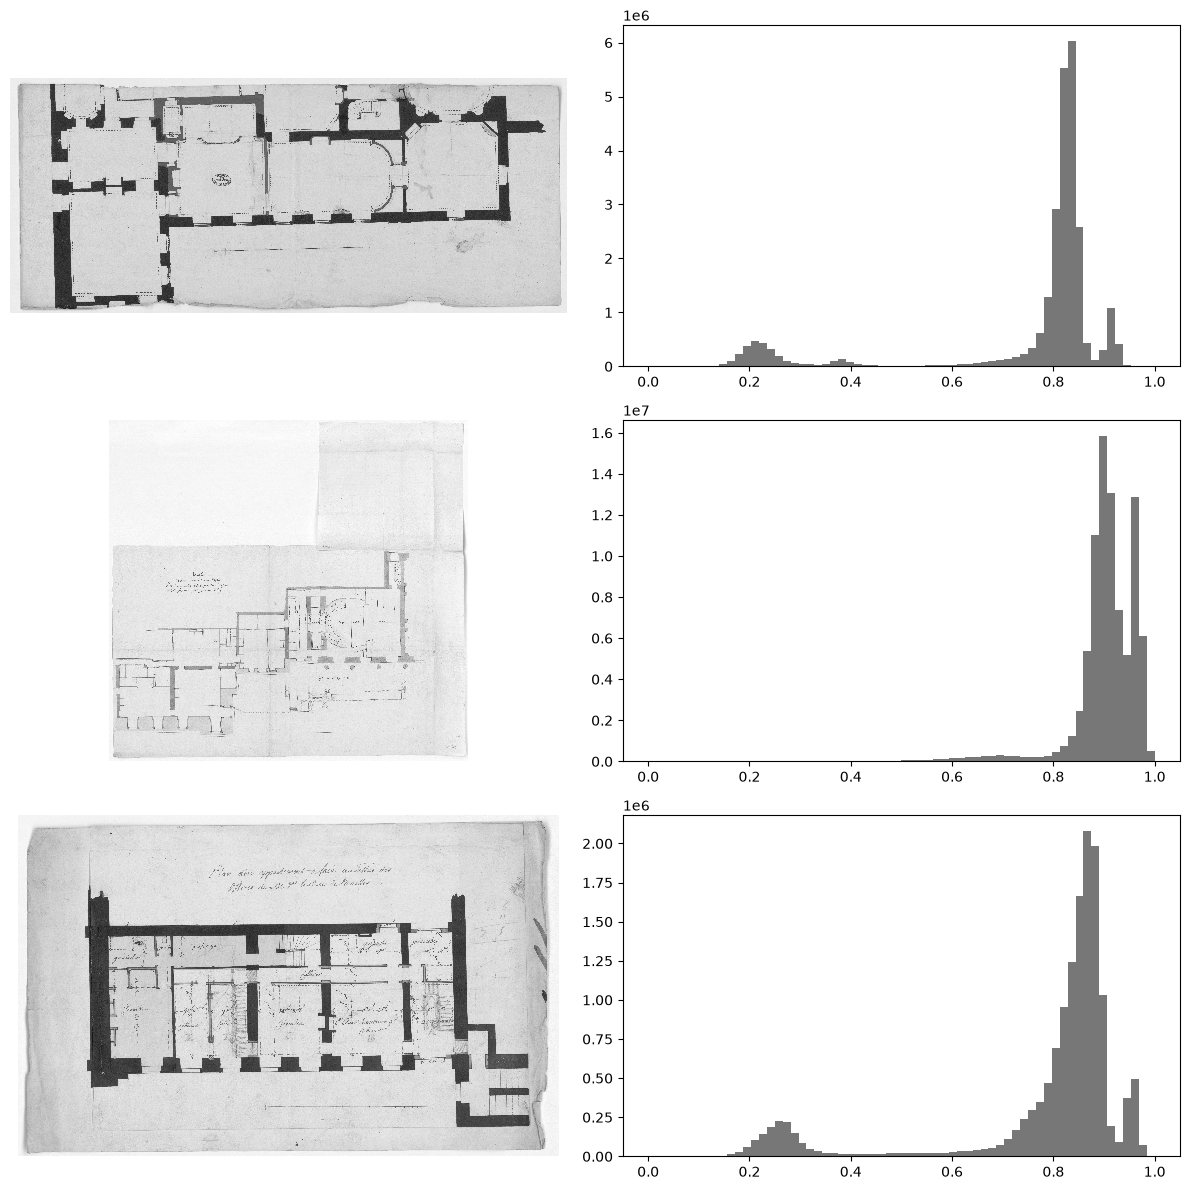

In [37]:
# Check out grayscale histogram
images_gray = [img.convert("L") for img in images]

histPlot(images_gray, graph_color="#777777")

Looking at the grayscale histograms, the bolder images have a clear little hump between 0.2 and 0.3. This must be the dark areas. Not particularly clear which spots are red, of course. The paler image does not have this clear split, however. Let's try to match to the histogram of the darker one.

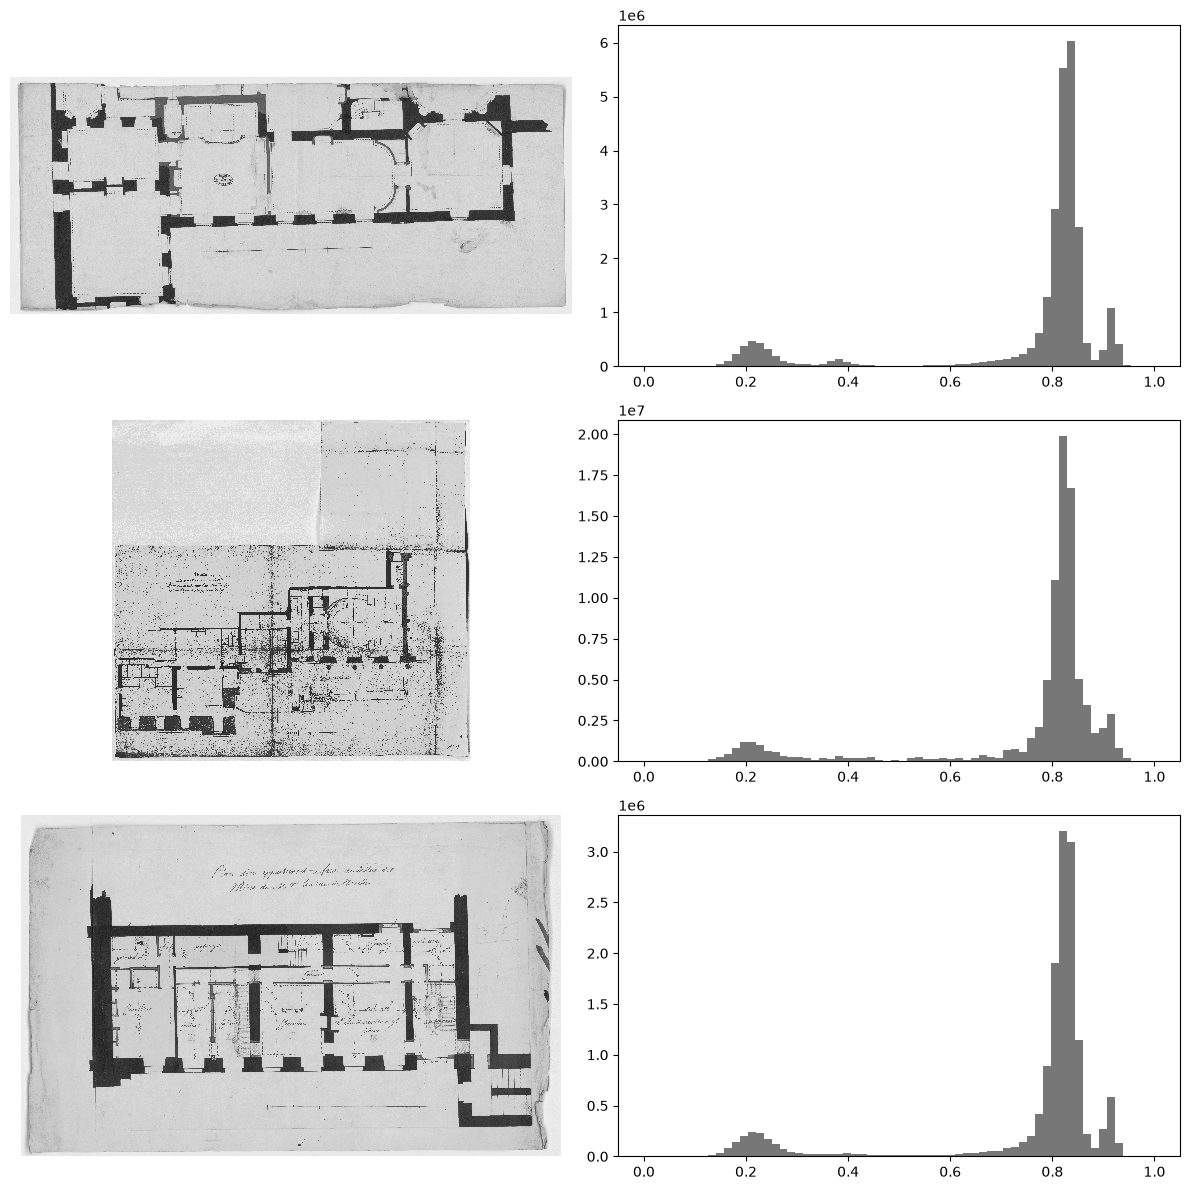

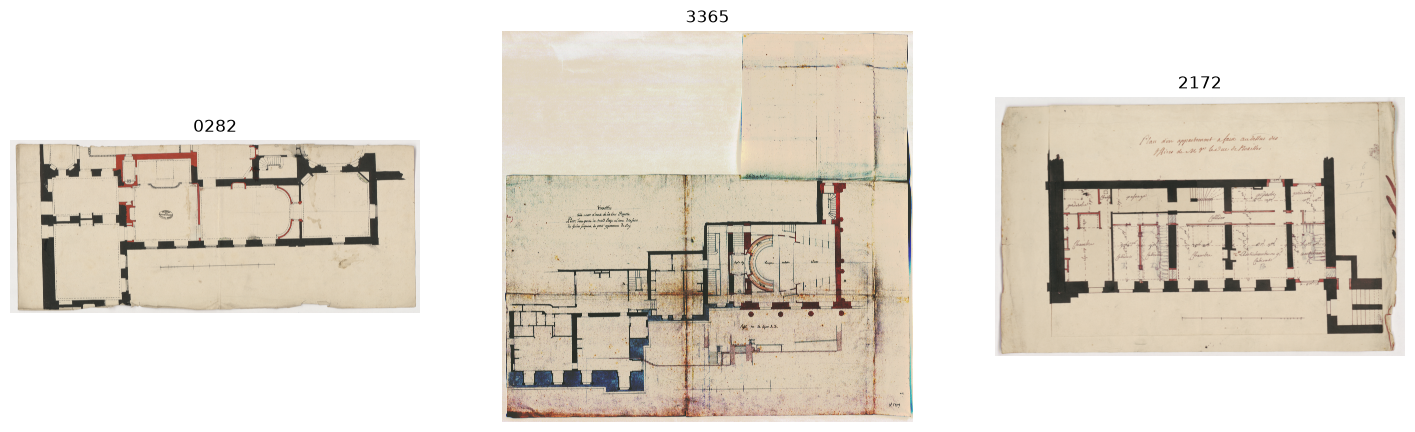

In [43]:
reference = np.asarray(images[0].convert("RGB"))
mimages = []

for img in images:
    mimages.append(Image.fromarray(match_histograms(np.asarray(img.convert("RGB")), reference, channel_axis=-1).clip(0, 255).astype(np.uint8)))

# Check out grayscale histogram
mimages_gray = [img.convert("L") for img in mimages]

histPlot(mimages_gray, graph_color="#777777")
# Plot normally
fig, axes = plt.subplots(1, len(mimages), figsize=(6 * len(images), 6))

for ax, img, img_id in zip(axes, mimages, img_ids):
    ax.imshow(img.convert("RGB"))
    ax.set_title(img_id)
    ax.axis("off")

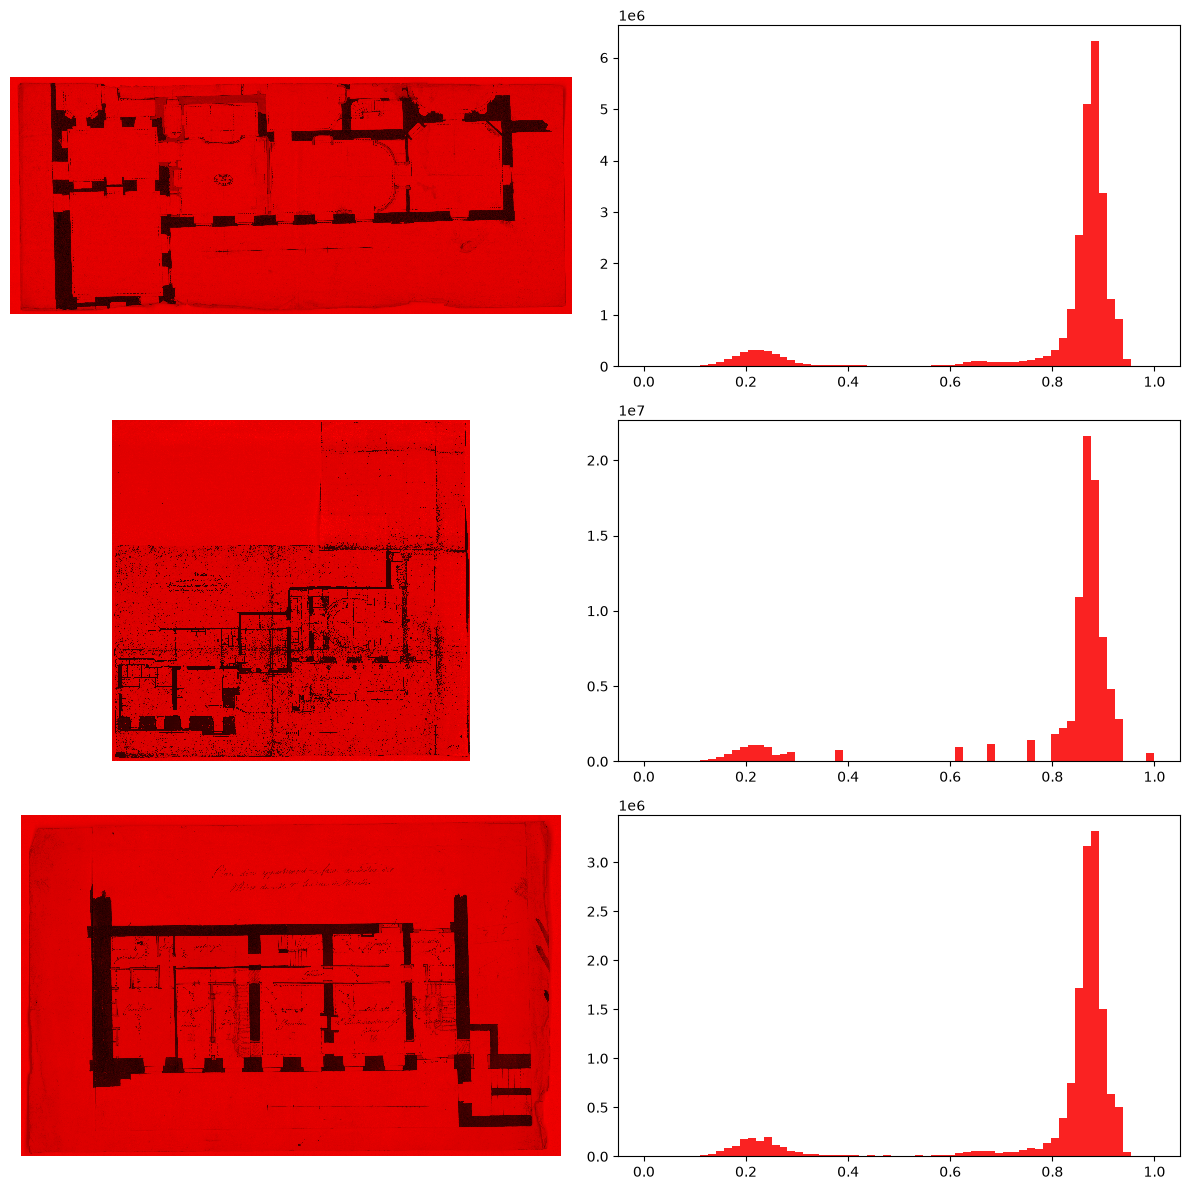

In [ ]:
# Check out red histogram
mimages_red = [img.convert("RGB").getchannel("R") for img in mimages]

from matplotlib.colors import LinearSegmentedColormap
histPlot(mimages_red, graph_color="#FA2222", img_color=LinearSegmentedColormap.from_list("black_red", ["red", "black"]))

In [40]:
# Attempt to preserve red
# Extension on the threshold filter, 3 reigons